<a href="https://colab.research.google.com/github/zinofiad824-cloud/-ppi-ml-learning/blob/main/peptide_machinelearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
    cross_validate,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

import sklearn

print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.6.1


In [2]:

rng = np.random.default_rng(42)

n_peptides = 400

molecular_weight = rng.uniform(
    800, 2500, n_peptides
)

hydrophobicity = rng.uniform(
    -1, 2, n_peptides
)

net_charge = rng.integers(
    -2, 5, n_peptides
)

hbd = rng.integers(
    5, 25, n_peptides
)

flexibility = rng.uniform(
    0.1, 0.9, n_peptides
)


In [3]:

noise = rng.normal(
    loc=0,
    scale=0.25,
    size=n_peptides
)

pkd = (
    6.5
    + 0.001 * (molecular_weight - 1500)
    + 0.5 * hydrophobicity
    + 0.15 * net_charge
    - 0.025 * hbd
    - 1.2 * (flexibility - 0.45) ** 2
    + 0.4 * np.sin(3 * hydrophobicity)
    + noise
)


In [4]:

df = pd.DataFrame({
    "Molecular_Weight": molecular_weight,
    "Hydrophobicity": hydrophobicity,
    "Net_Charge": net_charge.astype(float),
    "HBD": hbd.astype(float),
    "Flexibility": flexibility,
    "pKd": pkd
})

print(df.head())
print("Dataset shape:", df.shape)


   Molecular_Weight  Hydrophobicity  Net_Charge   HBD  Flexibility       pKd
0       2115.725283       -0.094218         0.0  22.0     0.553137  6.296280
1       1546.093348        1.755326         3.0   6.0     0.540727  7.408602
2       2259.616464        1.343882         3.0  12.0     0.762838  7.449131
3       1985.525649       -0.668235         0.0  14.0     0.668426  5.594516
4        960.101491        1.991104        -2.0  20.0     0.121262  5.668941
Dataset shape: (400, 6)


In [5]:

print(df.info())

print(df.describe().round(2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Molecular_Weight  400 non-null    float64
 1   Hydrophobicity    400 non-null    float64
 2   Net_Charge        400 non-null    float64
 3   HBD               400 non-null    float64
 4   Flexibility       400 non-null    float64
 5   pKd               400 non-null    float64
dtypes: float64(6)
memory usage: 18.9 KB
None
       Molecular_Weight  Hydrophobicity  Net_Charge     HBD  Flexibility  \
count            400.00          400.00      400.00  400.00       400.00   
mean            1644.13            0.48        0.92   14.58         0.50   
std              484.54            0.89        2.04    5.68         0.23   
min              812.52           -1.00       -2.00    5.00         0.10   
25%             1207.85           -0.29       -1.00   10.00         0.29   
50%             16

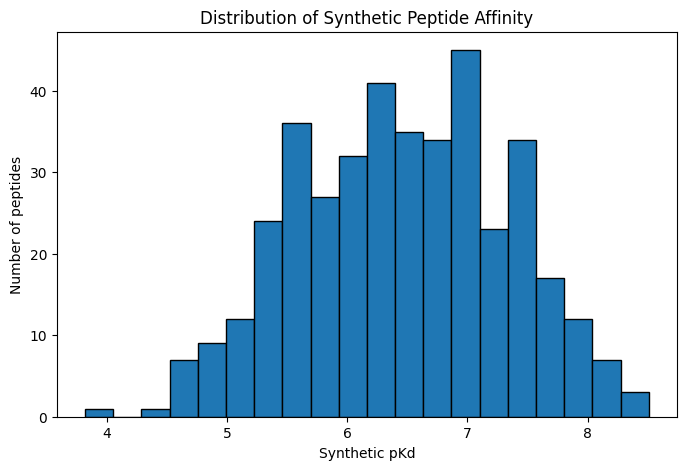

In [6]:

plt.figure(figsize=(8, 5))

plt.hist(
    df["pKd"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Synthetic pKd")
plt.ylabel("Number of peptides")
plt.title("Distribution of Synthetic Peptide Affinity")

plt.show()


In [7]:

X = df.drop(columns=["pKd"])

y = df["pKd"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (400, 5)
y shape: (400,)


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


Training observations: 320
Test observations: 80


In [10]:

models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=10,
            epsilon=0.1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            random_state=42
        ))
    ])
}


In [11]:

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [12]:

baseline_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        }
    )

    baseline_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

baseline_df = pd.DataFrame(baseline_results)

print(baseline_df.round(3))


               Model    MAE   RMSE     R2
0      Random Forest  0.256  0.322  0.850
1                SVR  0.276  0.350  0.822
2  Gradient Boosting  0.235  0.292  0.876


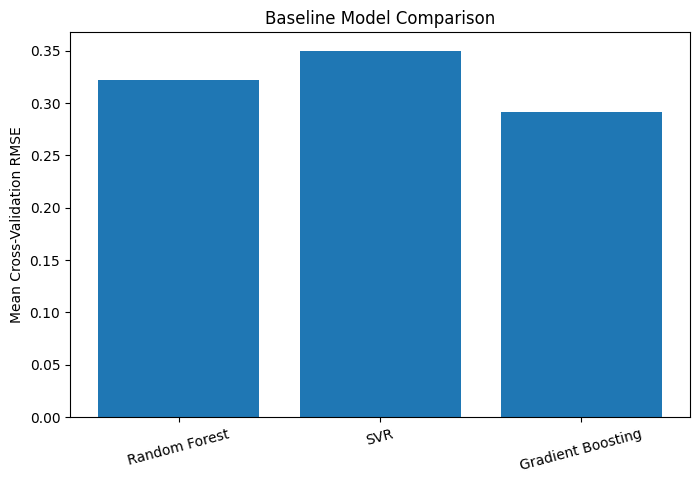

In [13]:

plt.figure(figsize=(8, 5))

plt.bar(
    baseline_df["Model"],
    baseline_df["RMSE"]
)

plt.ylabel("Mean Cross-Validation RMSE")
plt.title("Baseline Model Comparison")
plt.xticks(rotation=15)

plt.show()


In [14]:

parameter_grids = {
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [5, None],
        "model__min_samples_leaf": [1, 3]
    },

    "SVR": {
        "model__C": [1, 10, 100],
        "model__gamma": ["scale", 0.1],
        "model__epsilon": [0.05, 0.1]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3]
    }
}



In [15]:

optimized_searches = {}

optimization_results = []

for name, model in models.items():

    print("Optimizing:", name)

    search = GridSearchCV(
        estimator=model,
        param_grid=parameter_grids[name],
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    optimized_searches[name] = search

    optimization_results.append({
        "Model": name,
        "Best_CV_RMSE": -search.best_score_,
        "Best_Parameters": search.best_params_
    })

optimization_df = pd.DataFrame(
    optimization_results
)

optimization_df = optimization_df.sort_values(
    "Best_CV_RMSE"
)

print(optimization_df.to_string(index=False))


Optimizing: Random Forest
Optimizing: SVR
Optimizing: Gradient Boosting
            Model  Best_CV_RMSE                                                                      Best_Parameters
Gradient Boosting      0.287315     {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
    Random Forest      0.319284 {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
              SVR      0.326523                         {'model__C': 1, 'model__epsilon': 0.05, 'model__gamma': 0.1}


In [16]:

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)


In [17]:

selection_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough"),
    ("model", RandomForestRegressor(random_state=42))
])

selection_grid = [
    {
        "scaler": ["passthrough"],
        "model": [
            RandomForestRegressor(random_state=42)
        ],
        "model__n_estimators": [100, 200],
        "model__max_depth": [5, None],
        "model__min_samples_leaf": [1, 3]
    },

    {
        "scaler": [StandardScaler()],
        "model": [SVR(kernel="rbf")],
        "model__C": [1, 10, 100],
        "model__gamma": ["scale", 0.1],
        "model__epsilon": [0.05, 0.1]
    },

    {
        "scaler": ["passthrough"],
        "model": [
            GradientBoostingRegressor(random_state=42)
        ],
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [2, 3]
    }
]


In [18]:

model_selector = GridSearchCV(
    estimator=selection_pipeline,
    param_grid=selection_grid,
    cv=inner_cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    refit=True
)


In [19]:

nested_scores = cross_val_score(
    model_selector,
    X_train,
    y_train,
    cv=outer_cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

nested_rmse = -nested_scores

print("Outer-fold RMSE:")
print(nested_rmse)

print(
    "Mean nested RMSE:",
    round(nested_rmse.mean(), 3)
)

print(
    "Standard deviation:",
    round(nested_rmse.std(ddof=1), 3)
)


Outer-fold RMSE:
[0.22869689 0.25567591 0.31208259 0.25984588 0.36874041]
Mean nested RMSE: 0.285
Standard deviation: 0.056


In [20]:

model_selector.fit(X_train, y_train)

final_model = model_selector.best_estimator_

print("Selected model:")
print(final_model)

print("Selected parameters:")
print(model_selector.best_params_)


Selected model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', 'passthrough'),
                ('model',
                 GradientBoostingRegressor(max_depth=2, random_state=42))])
Selected parameters:
{'model': GradientBoostingRegressor(random_state=42), 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100, 'scaler': 'passthrough'}


In [21]:

test_predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(
    y_test,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(
    y_test,
    test_predictions
)

print(f"Test MAE: {test_mae:.3f}")
print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test R2: {test_r2:.3f}")


Test MAE: 0.272
Test RMSE: 0.333
Test R2: 0.872


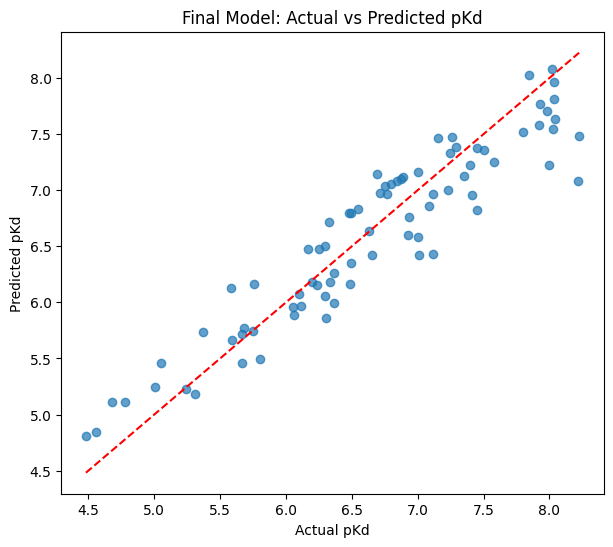

In [22]:

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

minimum = min(
    y_test.min(),
    test_predictions.min()
)

maximum = max(
    y_test.max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")
plt.title("Final Model: Actual vs Predicted pKd")

plt.show()


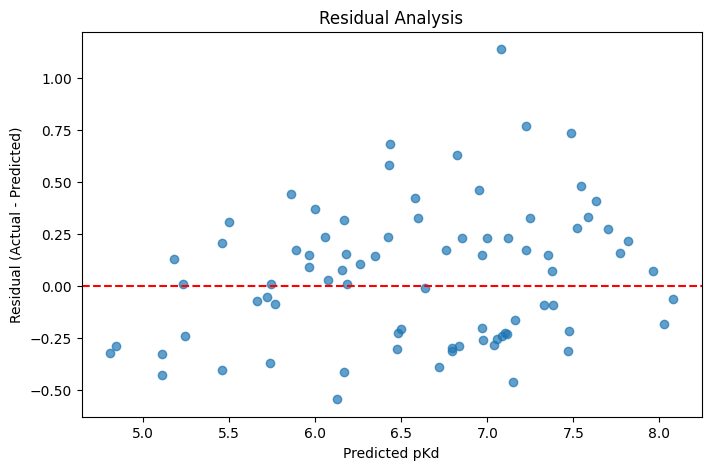

In [23]:

residuals = (
    y_test.to_numpy() - test_predictions
)

plt.figure(figsize=(8, 5))

plt.scatter(
    test_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--",
    color="red"
)

plt.xlabel("Predicted pKd")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")

plt.show()


In [24]:

importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df.round(3))




            Feature  Importance    Std
1    Hydrophobicity       0.458  0.040
0  Molecular_Weight       0.446  0.049
2        Net_Charge       0.236  0.017
3               HBD       0.035  0.009
4       Flexibility       0.005  0.004


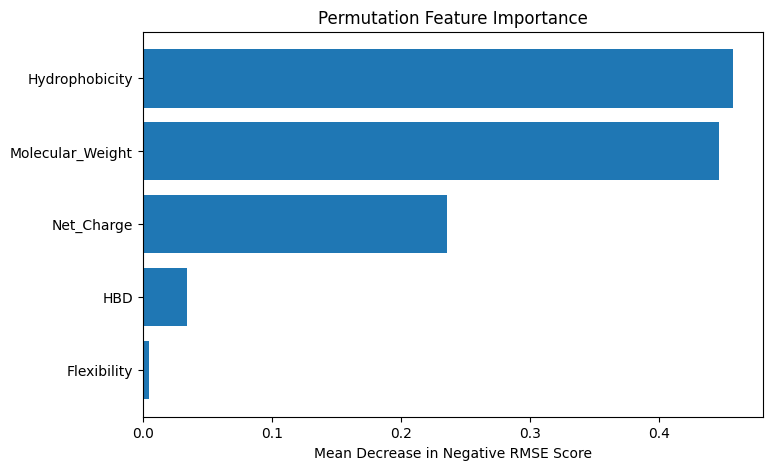

In [25]:

plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Mean Decrease in Negative RMSE Score")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()

plt.show()


In [26]:

new_peptide = pd.DataFrame({
    "Molecular_Weight": [1650],
    "Hydrophobicity": [0.7],
    "Net_Charge": [2],
    "HBD": [14],
    "Flexibility": [0.35]
})

print(new_peptide)


   Molecular_Weight  Hydrophobicity  Net_Charge  HBD  Flexibility
0              1650             0.7           2   14         0.35


In [27]:

predicted_pkd = final_model.predict(
    new_peptide
)[0]

print(f"Predicted pKd: {predicted_pkd:.3f}")


Predicted pKd: 7.239


In [28]:

from sklearn.model_selection import GroupKFold

example_groups = np.array([
    "Family_A",
    "Family_A",
    "Family_A",
    "Family_B",
    "Family_B",
    "Family_C",
    "Family_C",
    "Family_C",
    "Family_D",
    "Family_D"
])

group_cv = GroupKFold(n_splits=4)

example_X = pd.DataFrame({
    "Descriptor": np.arange(10)
})

example_y = np.arange(10) * 0.1

for fold, (train_idx, val_idx) in enumerate(
    group_cv.split(
        example_X,
        example_y,
        groups=example_groups
    ),
    start=1
):

    training_families = set(
        example_groups[train_idx]
    )

    validation_families = set(
        example_groups[val_idx]
    )

    overlap = training_families.intersection(
        validation_families
    )

    print(f"Fold {fold}")
    print("Training families:", training_families)
    print("Validation families:", validation_families)
    print("Overlap:", overlap)
    print("----------------------")


Fold 1
Training families: {np.str_('Family_D'), np.str_('Family_A'), np.str_('Family_B')}
Validation families: {np.str_('Family_C')}
Overlap: set()
----------------------
Fold 2
Training families: {np.str_('Family_C'), np.str_('Family_D'), np.str_('Family_B')}
Validation families: {np.str_('Family_A')}
Overlap: set()
----------------------
Fold 3
Training families: {np.str_('Family_C'), np.str_('Family_A'), np.str_('Family_B')}
Validation families: {np.str_('Family_D')}
Overlap: set()
----------------------
Fold 4
Training families: {np.str_('Family_D'), np.str_('Family_A'), np.str_('Family_C')}
Validation families: {np.str_('Family_B')}
Overlap: set()
----------------------
